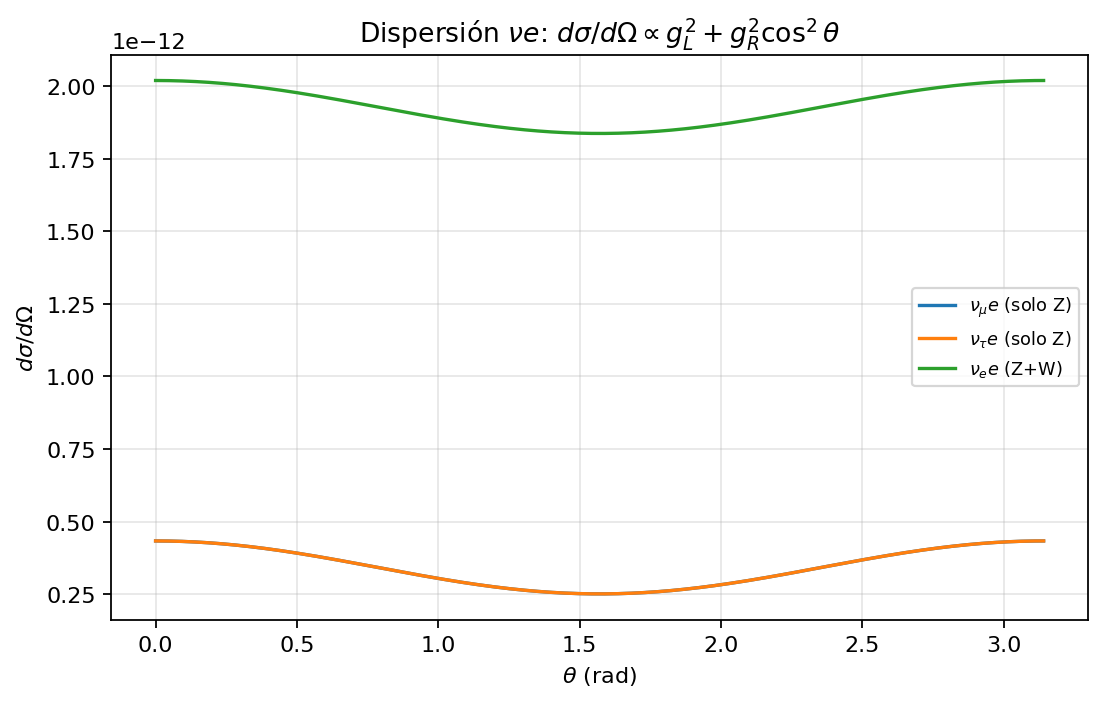

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Constantes
G_F = 1.1663787e-5  # GeV^-2
# Conversión opcional: 1 GeV^-2 = 0.389379e-27 cm^2
GEV2_TO_CM2 = 0.389379e-27

# (g_L, g_R) de tu tabla
processes = {
    r'$\nu_\mu e$ (solo Z)': (-0.27, 0.23),
    r'$\nu_\tau e$ (solo Z)': (-0.27, 0.23),
    r'$\nu_e e$ (Z+W)': (0.73, 0.23),
}

# Parámetros del barrido angular
theta = np.linspace(0, np.pi, 600)

# Elige s (GeV^2). Para comparar formas, cualquier valor sirve (solo reescala).
s = 1.0  # GeV^2

# Prefactor: dσ/dΩ = (G_F^2 s / (4π^2)) (g_L^2 + g_R^2 cos^2θ)
pref = (G_F**2 * s) / (4 * math.pi**2)  # en GeV^-2

# Si quieres ver en cm^2 en vez de GeV^-2, descomenta esta línea:
# pref *= GEV2_TO_CM2

plt.figure(figsize=(7, 4.5), dpi=160)

for name, (gL, gR) in processes.items():
    ds = pref * (gL**2 + (gR**2) * (np.cos(theta)**2))
    plt.plot(theta, ds, label=name)

plt.xlabel(r'$\theta$ (rad)')
plt.ylabel(r'$d\sigma/d\Omega$')
plt.title(r'Dispersión $\nu e$: $d\sigma/d\Omega \propto g_L^2 + g_R^2\cos^2\theta$')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("nu_e_dsig_domega_vs_theta.pdf")
plt.show()


In [3]:
from google.colab import drive
import shutil

# Montar Google Drive
drive.mount('/content/drive')

# Ruta del archivo generado (ajústala si es necesario)
archivo_origen = "nu_e_dsig_domega_vs_theta.pdf"

# Ruta destino en tu Drive
archivo_destino = "/content/drive/MyDrive/nu_e_dsig_domega_vs_theta.pdf"

# Copiar archivo
shutil.copy(archivo_origen, archivo_destino)

print("Archivo guardado en tu Google Drive.")

Mounted at /content/drive
Archivo guardado en tu Google Drive.


In [4]:
from google.colab import files
files.download("nu_e_dsig_domega_vs_theta.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/tmp/ipython-input-1860966862.py:49: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  norm = np.trapz(f, u_grid)  # normalización en [-1,1]


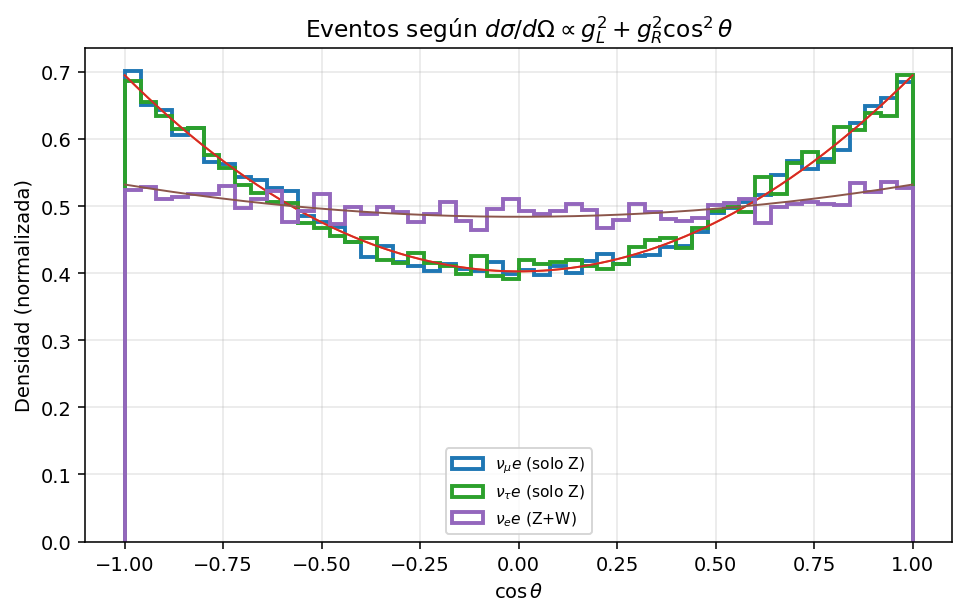

In [10]:
######### Ahora un montecarlo
import numpy as np
import matplotlib.pyplot as plt

def generate_nu_scatter(N=100000, gL=-0.27, gR=0.23):
    """
    Genera cos(theta) ~ p(u) ∝ gL^2 + gR^2 u^2, con u ∈ [-1,1]
    usando accept-reject.
    """
    cos_list = []

    # cota superior de f(u) en [-1,1]:
    # como u^2 <= 1, el máximo es gL^2 + gR^2
    f_max = gL**2 + gR**2

    while len(cos_list) < N:
        u = 2*np.random.rand() - 1   # cos(theta) uniforme en [-1,1]
        f = gL**2 + (gR**2) * (u**2)

        if np.random.rand() * f_max < f:
            cos_list.append(u)

    return np.array(cos_list)

# Parámetros (tu tabla)
processes = {
    r'$\nu_\mu e$ (solo Z)': (-0.27, 0.23),
    r'$\nu_\tau e$ (solo Z)': (-0.27, 0.23),
    r'$\nu_e e$ (Z+W)': (0.73, 0.23),
}

# Generar y graficar
N = 100000
bins = 50

plt.figure(figsize=(7,4.5), dpi=140)

# Para comparar también pongo la curva teórica normalizada
u_grid = np.linspace(-1, 1, 500)

for label, (gL, gR) in processes.items():
    samples = generate_nu_scatter(N=N, gL=gL, gR=gR)

    # hist
    plt.hist(samples, bins=bins, density=True, histtype='step', linewidth=2, label=label)

    # curva teórica normalizada en u
    f = gL**2 + (gR**2) * (u_grid**2)
    norm = np.trapz(f, u_grid)  # normalización en [-1,1]
    plt.plot(u_grid, f/norm, linewidth=1)

plt.xlabel(r'$\cos\theta$')
plt.ylabel('Densidad (normalizada)')
plt.title(r'Eventos según $d\sigma/d\Omega \propto g_L^2 + g_R^2\cos^2\theta$')
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("DistribucionAngular.pdf")
plt.show()


In [11]:
from google.colab import files
files.download("DistribucionAngular.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/tmp/ipython-input-2259710811.py:56: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  norm = np.trapz(f, u_grid)


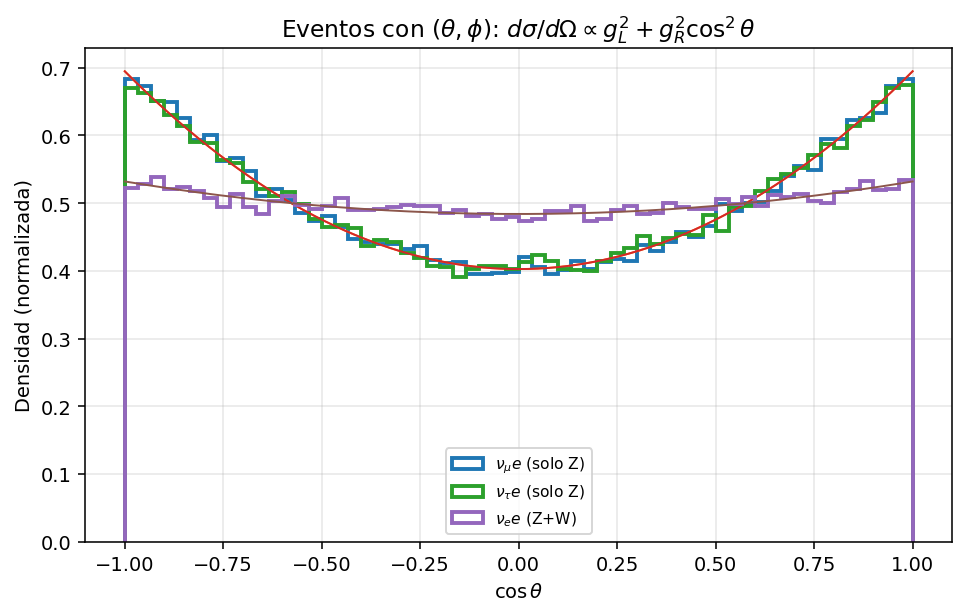

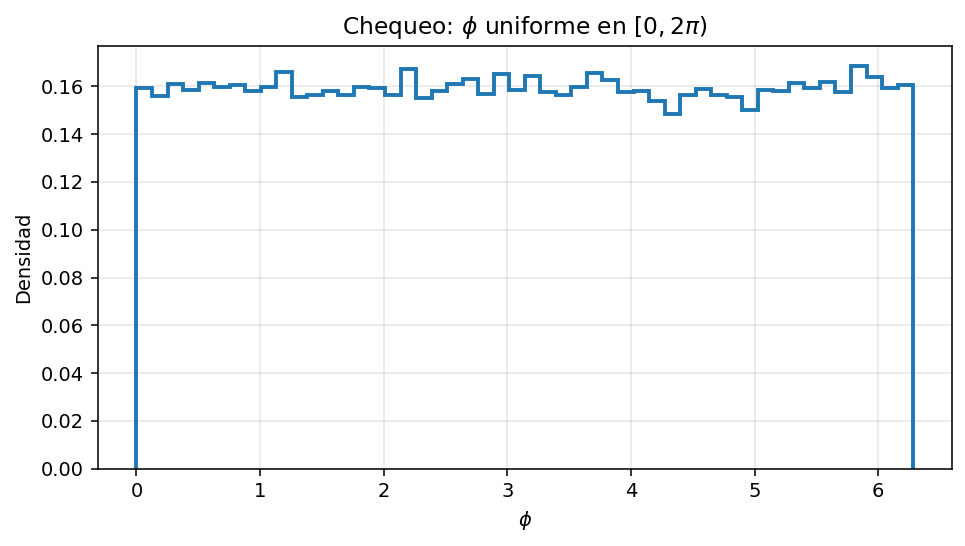

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def generate_nu_scatter_angles(N=100000, gL=-0.27, gR=0.23, return_direction=True):
    """
    Genera eventos con distribución:
      dσ/dΩ ∝ gL^2 + gR^2 cos^2θ
    Devuelve arrays theta, phi (y opcionalmente direcciones unitarias nx,ny,nz).
    """
    # accept-reject en u = cosθ ∈ [-1,1]
    f_max = gL**2 + gR**2  # máximo en |u|=1
    u = np.empty(N)
    i = 0
    while i < N:
        u_try = 2*np.random.rand() - 1
        f = gL**2 + (gR**2) * (u_try**2)
        if np.random.rand() * f_max < f:
            u[i] = u_try
            i += 1

    theta = np.arccos(u)
    phi = 2*np.pi*np.random.rand(N)

    if not return_direction:
        return theta, phi

    sinth = np.sin(theta)
    nx = sinth * np.cos(phi)
    ny = sinth * np.sin(phi)
    nz = np.cos(theta)
    return theta, phi, nx, ny, nz


# ---- Ejemplo de uso con tu tabla ----
processes = {
    r'$\nu_\mu e$ (solo Z)': (-0.27, 0.23),
    r'$\nu_\tau e$ (solo Z)': (-0.27, 0.23),
    r'$\nu_e e$ (Z+W)': (0.73, 0.23),
}

N = 200000
bins = 60

plt.figure(figsize=(7,4.5), dpi=140)

u_grid = np.linspace(-1, 1, 600)

for label, (gL, gR) in processes.items():
    theta, phi, nx, ny, nz = generate_nu_scatter_angles(N=N, gL=gL, gR=gR)

    # hist en cosθ (nz)
    plt.hist(nz, bins=bins, density=True, histtype='step', linewidth=2, label=label)

    # curva teórica normalizada en u
    f = gL**2 + (gR**2) * (u_grid**2)
    norm = np.trapz(f, u_grid)
    plt.plot(u_grid, f/norm, linewidth=1)

plt.xlabel(r'$\cos\theta$')
plt.ylabel('Densidad (normalizada)')
plt.title(r'Eventos con $(\theta,\phi)$: $d\sigma/d\Omega \propto g_L^2 + g_R^2\cos^2\theta$')
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


# ---- Extra: verificar que φ es uniforme ----
# Genera uno (por ejemplo νe e)
theta, phi, *_ = generate_nu_scatter_angles(N=100000, gL=0.73, gR=0.23)

plt.figure(figsize=(7,4.0), dpi=140)
plt.hist(phi, bins=50, density=True, histtype='step', linewidth=2)
plt.xlabel(r'$\phi$')
plt.ylabel('Densidad')
plt.title(r'Chequeo: $\phi$ uniforme en $[0,2\pi)$')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

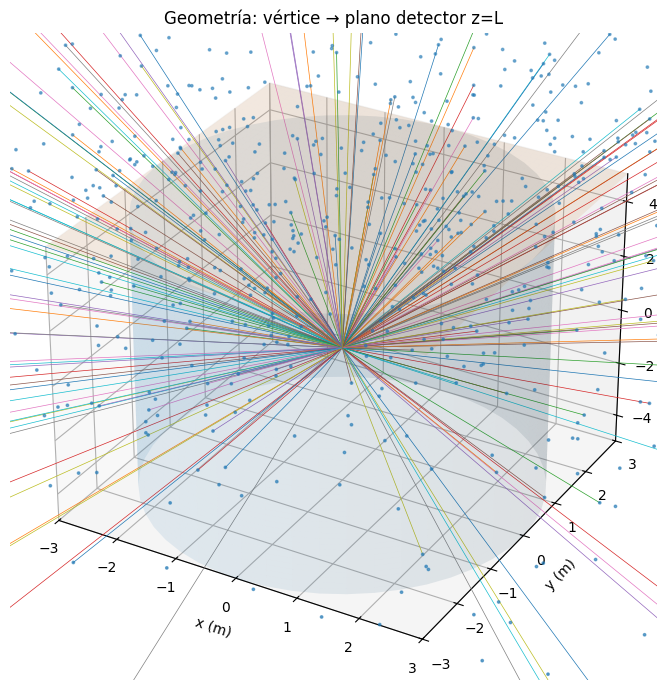

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# -----------------------------
# Generador angular
# -----------------------------
def generate_nu_scatter_angles(N=5000, gL=0.73, gR=0.23):
    f_max = gL**2 + gR**2
    u = []

    while len(u) < N:
        u_try = 2*np.random.rand() - 1
        f = gL**2 + (gR**2)*(u_try**2)
        if np.random.rand()*f_max < f:
            u.append(u_try)

    u = np.array(u)
    theta = np.arccos(u)
    phi = 2*np.pi*np.random.rand(N)

    return theta, phi


# -----------------------------
# Impacto en plano z=L
# -----------------------------
def impact_on_plane(theta, phi, L=5.0):
    cos_theta = np.cos(theta)
    mask = cos_theta > 0

    theta = theta[mask]
    phi = phi[mask]

    r = L * np.tan(theta)

    x = r * np.cos(phi)
    y = r * np.sin(phi)

    return x, y, theta, phi


# Parámetros del detector
L = 5.0      # posición del plano (m)
R_det = 3.0  # radio cilindro (m)
H_det = 10.0 # altura total cilindro (m)

# Generar eventos
theta, phi = generate_nu_scatter_angles(N=3000)
x, y, theta, phi = impact_on_plane(theta, phi, L=L)

# -----------------------------
# Visualización 3D
# -----------------------------
fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection='3d')

# --- Dibujar cilindro ---
z = np.linspace(-H_det/2, H_det/2, 50)
phi_c = np.linspace(0, 2*np.pi, 50)
phi_c, z = np.meshgrid(phi_c, z)
x_c = R_det*np.cos(phi_c)
y_c = R_det*np.sin(phi_c)

ax.plot_surface(x_c, y_c, z, alpha=0.1)

# --- Dibujar plano z=L ---
xx = np.linspace(-R_det, R_det, 50)
yy = np.linspace(-R_det, R_det, 50)
xx, yy = np.meshgrid(xx, yy)
zz = np.ones_like(xx)*L
ax.plot_surface(xx, yy, zz, alpha=0.1)

# --- Dibujar algunas trayectorias ---
for i in range(200):
    ax.plot([0, x[i]], [0, y[i]], [0, L], linewidth=0.5)

# --- Dibujar puntos de impacto ---
ax.scatter(x, y, L*np.ones_like(x), s=3)

ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_zlabel("z (m)")
ax.set_title("Geometría: vértice → plano detector z=L")

ax.set_xlim(-R_det, R_det)
ax.set_ylim(-R_det, R_det)
ax.set_zlim(-H_det/2, H_det/2)

plt.tight_layout()
plt.savefig("DistribucionEspacial.pdf")
plt.show()

In [15]:
files.download("DistribucionEspacial.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>